# Day 034 | Dimensionality Reduction (PCA, SVD)

## 100 Days of ML for Geotechnical Engineering
**Phase:** Data Science Essentials

**Author:** Ripon Chandra Malo  
**Date:** 2026

---

## What We Will Learn Today

| Concept | What It Means | Geotechnical Example |
|---------|--------------|---------------------|
| **Curse of Dimensionality** | Too many features, too few samples | 20 correlated soil tests on 50 samples |
| **PCA** | Find directions of maximum variance | Reduce 8 soil measurements to 2-3 components |
| **Covariance Matrix** | Measures how features co-vary | Depth and N-value increase together |
| **Eigendecomposition** | Find principal directions | The axes along which soil data varies most |
| **Explained Variance** | How much information each PC captures | PC1 captures 45% of all soil variation |
| **SVD** | Matrix factorization (generalized PCA) | Decompose soil data matrix into components |
| **t-SNE** | Nonlinear visualization technique | Visualize soil clusters in 2D |

---

## Our Geotechnical Problem

Our borehole dataset has 8 numerical features: depth, N_value, water_content, unit_weight, fines_content, liquid_limit, plasticity_index, and a computed feature. Many of these are **correlated** (e.g., liquid_limit and plasticity_index move together; fines_content and water_content are related).

**Goal:** Reduce 8 features to 2-3 principal components that capture most of the variance, and visualize how soil types cluster in this reduced space.

---

## Part 1: The Curse of Dimensionality

When you have many features relative to samples, strange things happen:
- **Distances become meaningless** — all points are equally far apart in high dimensions
- **Overfitting becomes easy** — models memorize noise instead of learning patterns
- **Visualization is impossible** — you cannot plot 8D data directly

In geotechnical engineering, we often collect many correlated measurements (LL, PL, PI, water content, fines content) that essentially measure overlapping aspects of the soil.

---

In [1]:
# ─────────────────────────────────────────────────────
# LOAD AND PREPARE SOIL DATASET
# ─────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

# ── Load borehole data ──
df = pd.read_csv("../Day_031/raw_soil_data.csv")

# ── Select numerical features ──
num_cols = ['depth', 'N_value', 'water_content', 'unit_weight', 
            'fines_content', 'liquid_limit', 'plasticity_index']

# ── Add an engineered feature for more dimensions ──
df['N_over_depth'] = df['N_value'] / df['depth']
num_cols.append('N_over_depth')

X = df[num_cols].copy()
soil_labels = df['soil_type'].values

print("Dataset for Dimensionality Reduction")
print("=" * 55)
print(f"Samples: {X.shape[0]}, Features: {X.shape[1]}")
print(f"Features: {num_cols}")
print(f"Soil types: {df['soil_type'].nunique()} unique")
print()
print(X.describe().round(2))

Dataset for Dimensionality Reduction
Samples: 80, Features: 8
Features: ['depth', 'N_value', 'water_content', 'unit_weight', 'fines_content', 'liquid_limit', 'plasticity_index', 'N_over_depth']
Soil types: 8 unique

       depth  N_value  water_content  unit_weight  fines_content  \
count  80.00    80.00          80.00        80.00          80.00   
mean   16.00    29.41          18.77        18.60          36.66   
std     7.50    11.89          10.11         1.24          30.42   
min     1.80     5.00           5.00        15.72           0.00   
25%    10.05    22.00          10.22        17.65           9.30   
50%    16.60    28.50          16.90        18.64          31.15   
75%    22.12    35.25          27.45        19.59          64.62   
max    28.00    64.00          46.20        20.96          96.60   

       liquid_limit  plasticity_index  N_over_depth  
count         80.00             80.00         80.00  
mean          19.25             11.47          2.62  
std      

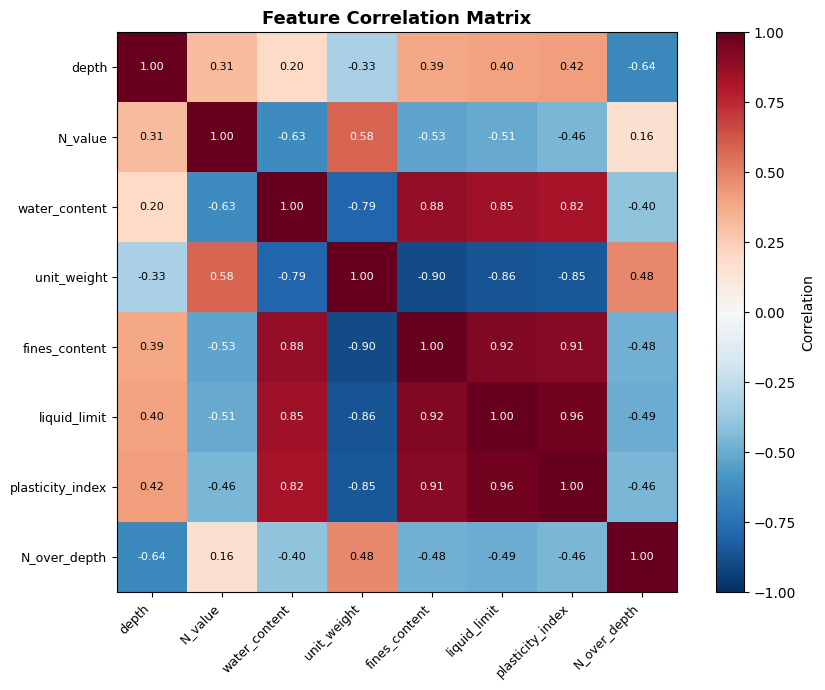

Highly Correlated Feature Pairs (|r| > 0.5):
──────────────────────────────────────────────────
  depth                <-> N_over_depth          r = -0.645
  N_value              <-> water_content         r = -0.630
  N_value              <-> unit_weight           r = +0.585
  N_value              <-> fines_content         r = -0.527
  N_value              <-> liquid_limit          r = -0.507
  water_content        <-> unit_weight           r = -0.791
  water_content        <-> fines_content         r = +0.878
  water_content        <-> liquid_limit          r = +0.847
  water_content        <-> plasticity_index      r = +0.821
  unit_weight          <-> fines_content         r = -0.895
  unit_weight          <-> liquid_limit          r = -0.860
  unit_weight          <-> plasticity_index      r = -0.846
  fines_content        <-> liquid_limit          r = +0.923
  fines_content        <-> plasticity_index      r = +0.906
  liquid_limit         <-> plasticity_index      r = +0.963

Cor

In [2]:
# ─────────────────────────────────────────────────────
# CORRELATION MATRIX — See the redundancy
# ─────────────────────────────────────────────────────
corr_matrix = X.corr()

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr_matrix.values, cmap='RdBu_r', vmin=-1, vmax=1)

# Labels
ax.set_xticks(range(len(num_cols)))
ax.set_yticks(range(len(num_cols)))
ax.set_xticklabels(num_cols, rotation=45, ha='right', fontsize=9)
ax.set_yticklabels(num_cols, fontsize=9)

# Annotate
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        val = corr_matrix.values[i, j]
        color = 'white' if abs(val) > 0.5 else 'black'
        ax.text(j, i, f'{val:.2f}', ha='center', va='center', 
                fontsize=8, color=color)

plt.colorbar(im, label='Correlation')
ax.set_title('Feature Correlation Matrix', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig('correlation_matrix.png', dpi=100, bbox_inches='tight')
plt.show()

# ── Find highly correlated pairs ──
print("Highly Correlated Feature Pairs (|r| > 0.5):")
print("─" * 50)
for i in range(len(num_cols)):
    for j in range(i+1, len(num_cols)):
        r = abs(corr_matrix.values[i, j])
        if r > 0.5:
            print(f"  {num_cols[i]:20s} <-> {num_cols[j]:20s}  r = {corr_matrix.values[i,j]:+.3f}")
print()
print("Correlated features carry redundant information.")
print("PCA will combine them into fewer, uncorrelated components.")

## Part 2: PCA Step by Step

PCA (Principal Component Analysis) finds new axes (principal components) that:
1. Are **orthogonal** (uncorrelated) to each other
2. Are ordered by **variance explained** (PC1 captures the most variation)
3. Are **linear combinations** of the original features

Let us walk through the math step by step.

---

In [3]:
# ─────────────────────────────────────────────────────
# STEP 1: STANDARDIZE THE DATA
# ─────────────────────────────────────────────────────
# PCA is sensitive to feature scales.
# We must standardize so all features contribute equally.

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Step 1: Standardize")
print("─" * 40)
print(f"Before: mean(depth) = {X['depth'].mean():.1f}, std = {X['depth'].std():.1f}")
print(f"After:  mean(depth) = {X_scaled[:, 0].mean():.4f}, std = {X_scaled[:, 0].std():.4f}")
print()
print("All features now have mean=0, std=1.")

Step 1: Standardize
────────────────────────────────────────
Before: mean(depth) = 16.0, std = 7.5
After:  mean(depth) = -0.0000, std = 1.0000

All features now have mean=0, std=1.


In [4]:
# ─────────────────────────────────────────────────────
# STEP 2: COMPUTE THE COVARIANCE MATRIX
# ─────────────────────────────────────────────────────
# The covariance matrix captures how features co-vary.
# Diagonal = variance of each feature (all ~1 after scaling)
# Off-diagonal = covariance between feature pairs

cov_matrix = np.cov(X_scaled, rowvar=False)

print("Step 2: Covariance Matrix")
print("─" * 40)
print(f"Shape: {cov_matrix.shape} (8 features × 8 features)")
print()
print("Covariance Matrix (rounded):")
cov_df = pd.DataFrame(cov_matrix.round(3), columns=num_cols, index=num_cols)
print(cov_df.to_string())

Step 2: Covariance Matrix
────────────────────────────────────────
Shape: (8, 8) (8 features × 8 features)

Covariance Matrix (rounded):
                  depth  N_value  water_content  unit_weight  fines_content  liquid_limit  plasticity_index  N_over_depth
depth             1.013    0.319          0.204       -0.331          0.391         0.409             0.420        -0.653
N_value           0.319    1.013         -0.638        0.592         -0.534        -0.514            -0.466         0.164
water_content     0.204   -0.638          1.013       -0.801          0.889         0.858             0.832        -0.410
unit_weight      -0.331    0.592         -0.801        1.013         -0.907        -0.870            -0.857         0.483
fines_content     0.391   -0.534          0.889       -0.907          1.013         0.934             0.918        -0.485
liquid_limit      0.409   -0.514          0.858       -0.870          0.934         1.013             0.975        -0.499
plasticit

In [5]:
# ─────────────────────────────────────────────────────
# STEP 3: EIGENDECOMPOSITION
# ─────────────────────────────────────────────────────
# Eigenvalues = how much variance each PC captures
# Eigenvectors = the direction of each PC (the "recipe")

eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

# Sort by eigenvalue (largest first)
sorted_idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[sorted_idx]
eigenvectors = eigenvectors[:, sorted_idx]

print("Step 3: Eigendecomposition")
print("─" * 40)
print("Eigenvalues (variance captured by each PC):")
for i, ev in enumerate(eigenvalues):
    pct = ev / eigenvalues.sum() * 100
    bar = "█" * int(pct / 2)
    print(f"  PC{i+1}: {ev:.3f}  ({pct:5.1f}%)  {bar}")

print(f"\nTotal variance: {eigenvalues.sum():.3f}")
print(f"Sum should equal {len(num_cols)} (number of features after standardizing).")

Step 3: Eigendecomposition
────────────────────────────────────────
Eigenvalues (variance captured by each PC):
  PC1: 5.349  ( 66.0%)  █████████████████████████████████
  PC2: 1.582  ( 19.5%)  █████████
  PC3: 0.573  (  7.1%)  ███
  PC4: 0.209  (  2.6%)  █
  PC5: 0.157  (  1.9%)  
  PC6: 0.133  (  1.6%)  
  PC7: 0.065  (  0.8%)  
  PC8: 0.034  (  0.4%)  

Total variance: 8.101
Sum should equal 8 (number of features after standardizing).


Step 4: Select Number of Components
────────────────────────────────────────
  PC1: 0.660 (66.0%)  cumulative: 0.660 (66.0%)
  PC2: 0.195 (19.5%)  cumulative: 0.856 (85.6%)
  PC3: 0.071 (7.1%)  cumulative: 0.926 (92.6%) ← 90% threshold
  PC4: 0.026 (2.6%)  cumulative: 0.952 (95.2%)
  PC5: 0.019 (1.9%)  cumulative: 0.971 (97.1%)
  PC6: 0.016 (1.6%)  cumulative: 0.988 (98.8%)
  PC7: 0.008 (0.8%)  cumulative: 0.996 (99.6%)
  PC8: 0.004 (0.4%)  cumulative: 1.000 (100.0%)


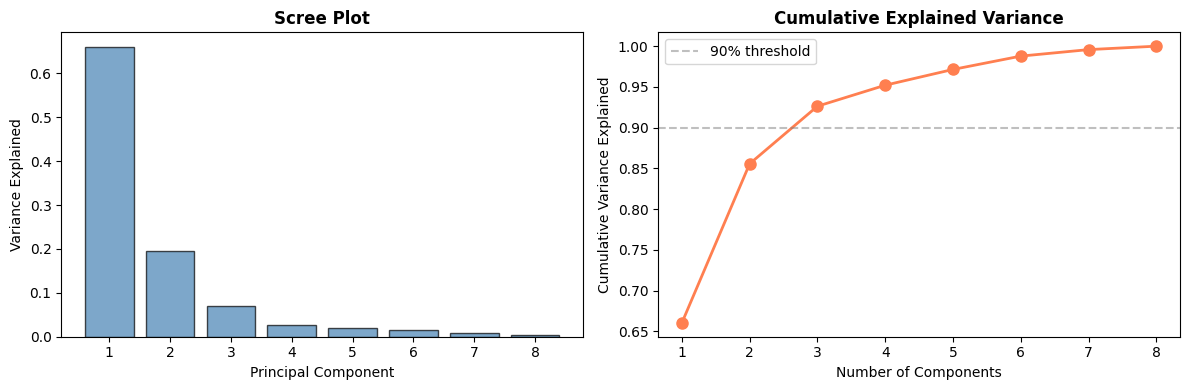

In [6]:
# ─────────────────────────────────────────────────────
# STEP 4: SELECT COMPONENTS
# ─────────────────────────────────────────────────────
# How many PCs do we need? Look at cumulative variance.

explained_var_ratio = eigenvalues / eigenvalues.sum()
cumulative_var = np.cumsum(explained_var_ratio)

print("Step 4: Select Number of Components")
print("─" * 40)
for i, (ratio, cum) in enumerate(zip(explained_var_ratio, cumulative_var)):
    marker = " ← 90% threshold" if cum >= 0.9 and (i == 0 or cumulative_var[i-1] < 0.9) else ""
    print(f"  PC{i+1}: {ratio:.3f} ({ratio*100:.1f}%)  cumulative: {cum:.3f} ({cum*100:.1f}%){marker}")

# ── Scree plot ──
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(range(1, len(eigenvalues)+1), explained_var_ratio, 
             color='steelblue', edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Variance Explained')
axes[0].set_title('Scree Plot', fontweight='bold')
axes[0].set_xticks(range(1, len(eigenvalues)+1))

axes[1].plot(range(1, len(eigenvalues)+1), cumulative_var, 
              'o-', color='coral', linewidth=2, markersize=8)
axes[1].axhline(y=0.9, color='gray', linestyle='--', alpha=0.5, label='90% threshold')
axes[1].set_xlabel('Number of Components')
axes[1].set_ylabel('Cumulative Variance Explained')
axes[1].set_title('Cumulative Explained Variance', fontweight='bold')
axes[1].set_xticks(range(1, len(eigenvalues)+1))
axes[1].legend()

plt.tight_layout()
plt.savefig('scree_plot.png', dpi=100, bbox_inches='tight')
plt.show()

## Part 3: PCA with sklearn

Now let us use sklearn's PCA class, which handles all the math internally.

---

In [7]:
# ─────────────────────────────────────────────────────
# SKLEARN PCA
# ─────────────────────────────────────────────────────
from sklearn.decomposition import PCA

# ── Fit PCA with all components first ──
pca_full = PCA()
pca_full.fit(X_scaled)

print("sklearn PCA — Full Decomposition")
print("=" * 55)
print(f"Components: {pca_full.n_components_}")
print(f"Explained variance ratio: {pca_full.explained_variance_ratio_.round(4)}")
print(f"Cumulative: {np.cumsum(pca_full.explained_variance_ratio_).round(4)}")
print()

# ── Now reduce to 2 components for visualization ──
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

print(f"Reduced to 2 components:")
print(f"  Original shape: {X_scaled.shape}")
print(f"  Reduced shape:  {X_pca_2d.shape}")
print(f"  Variance retained: {pca_2d.explained_variance_ratio_.sum():.1%}")

sklearn PCA — Full Decomposition
Components: 8
Explained variance ratio: [0.6603 0.1953 0.0707 0.0258 0.0194 0.0164 0.008  0.0042]
Cumulative: [0.6603 0.8556 0.9263 0.9521 0.9714 0.9878 0.9958 1.    ]

Reduced to 2 components:
  Original shape: (80, 8)
  Reduced shape:  (80, 2)
  Variance retained: 85.6%


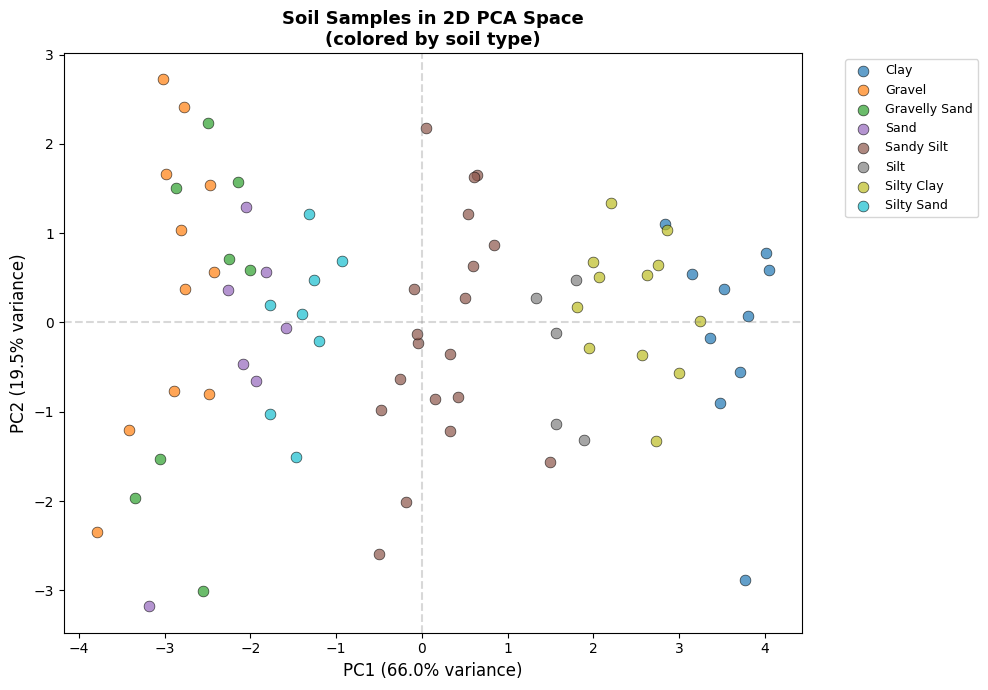

Observations:
  - Similar soil types should cluster together
  - Granular soils (Sand, Gravel) separate from fine soils (Clay, Silt)
  - PCA reveals natural groupings in 8D data using just 2 axes!


In [8]:
# ─────────────────────────────────────────────────────
# VISUALIZE SOIL SAMPLES IN 2D PCA SPACE
# ─────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 7))

# ── Color by soil type ──
unique_soils = sorted(df['soil_type'].unique())
colors = plt.cm.tab10(np.linspace(0, 1, len(unique_soils)))
color_map = dict(zip(unique_soils, colors))

for soil in unique_soils:
    mask = soil_labels == soil
    ax.scatter(X_pca_2d[mask, 0], X_pca_2d[mask, 1], 
               c=[color_map[soil]], label=soil, s=60, alpha=0.7, edgecolors='black', linewidth=0.5)

ax.set_xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]:.1%} variance)', fontsize=12)
ax.set_ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]:.1%} variance)', fontsize=12)
ax.set_title('Soil Samples in 2D PCA Space\n(colored by soil type)', fontweight='bold', fontsize=13)
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=9)
ax.axhline(0, color='gray', linestyle='--', alpha=0.3)
ax.axvline(0, color='gray', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.savefig('pca_2d_soil_types.png', dpi=100, bbox_inches='tight')
plt.show()

print("Observations:")
print("  - Similar soil types should cluster together")
print("  - Granular soils (Sand, Gravel) separate from fine soils (Clay, Silt)")
print("  - PCA reveals natural groupings in 8D data using just 2 axes!")

PC Loadings (how each original feature contributes)
                    PC1    PC2    PC3
depth             0.186  0.691  0.098
N_value          -0.254  0.545  0.504
water_content     0.392 -0.174  0.046
unit_weight      -0.403  0.068 -0.026
fines_content     0.418 -0.028  0.172
liquid_limit      0.418 -0.003  0.204
plasticity_index  0.410  0.013  0.292
N_over_depth     -0.258 -0.436  0.759



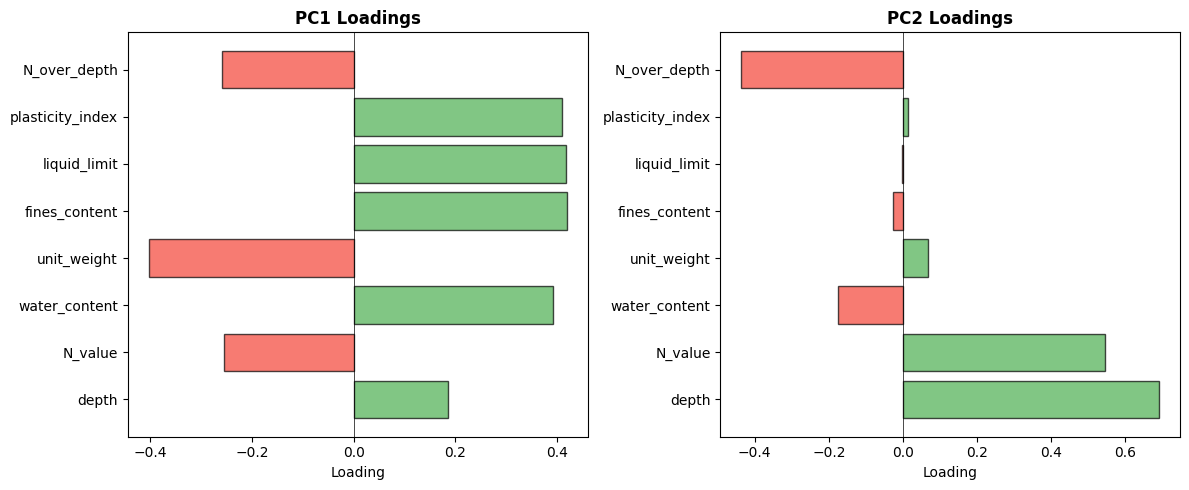

Interpretation:
  PC1: Likely captures the fine-grained vs coarse-grained axis
  PC2: Likely captures the depth/stress axis
  Positive loadings = feature increases in that PC direction


In [9]:
# ─────────────────────────────────────────────────────
# INTERPRETING THE COMPONENTS — What do PC1 and PC2 mean?
# ─────────────────────────────────────────────────────
print("PC Loadings (how each original feature contributes)")
print("=" * 60)

loadings = pd.DataFrame(
    pca_full.components_.T,
    columns=[f'PC{i+1}' for i in range(len(num_cols))],
    index=num_cols
)

print(loadings[['PC1', 'PC2', 'PC3']].round(3))
print()

# ── Visualize loadings for PC1 and PC2 ──
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for idx, ax in enumerate(axes):
    pc_loadings = loadings[f'PC{idx+1}']
    colors = ['#F44336' if v < 0 else '#4CAF50' for v in pc_loadings]
    ax.barh(num_cols, pc_loadings, color=colors, edgecolor='black', alpha=0.7)
    ax.set_xlabel('Loading')
    ax.set_title(f'PC{idx+1} Loadings', fontweight='bold')
    ax.axvline(0, color='black', linewidth=0.5)

plt.tight_layout()
plt.savefig('pca_loadings.png', dpi=100, bbox_inches='tight')
plt.show()

print("Interpretation:")
print("  PC1: Likely captures the fine-grained vs coarse-grained axis")
print("  PC2: Likely captures the depth/stress axis")
print("  Positive loadings = feature increases in that PC direction")

## Part 4: SVD — The Math Behind PCA

Singular Value Decomposition (SVD) decomposes any matrix into three components:

**X = U x S x V^T**

where:
- **U** = left singular vectors (sample directions)
- **S** = singular values (related to eigenvalues)
- **V** = right singular vectors (feature directions = PC loadings)

PCA is actually implemented using SVD internally (it is more numerically stable than eigendecomposition).

---

In [10]:
# ─────────────────────────────────────────────────────
# SVD — Matrix Factorization
# ─────────────────────────────────────────────────────

U, S, Vt = np.linalg.svd(X_scaled, full_matrices=False)

print("SVD Decomposition of Soil Data")
print("=" * 55)
print(f"X shape:  {X_scaled.shape} (samples × features)")
print(f"U shape:  {U.shape} (samples × components)")
print(f"S shape:  {S.shape} (singular values)")
print(f"Vt shape: {Vt.shape} (components × features)")
print()

# ── Singular values relate to eigenvalues ──
eigenvalues_from_svd = S**2 / (len(X_scaled) - 1)
variance_ratio_svd = eigenvalues_from_svd / eigenvalues_from_svd.sum()

print("Variance from SVD vs PCA (should match):")
print("─" * 40)
for i in range(min(5, len(S))):
    print(f"  PC{i+1}: SVD = {variance_ratio_svd[i]:.4f}  |  PCA = {pca_full.explained_variance_ratio_[i]:.4f}")

print()
print("SVD and PCA give the same result!")
print("sklearn uses SVD internally for numerical stability.")

SVD Decomposition of Soil Data
X shape:  (80, 8) (samples × features)
U shape:  (80, 8) (samples × components)
S shape:  (8,) (singular values)
Vt shape: (8, 8) (components × features)

Variance from SVD vs PCA (should match):
────────────────────────────────────────
  PC1: SVD = 0.6603  |  PCA = 0.6603
  PC2: SVD = 0.1953  |  PCA = 0.1953
  PC3: SVD = 0.0707  |  PCA = 0.0707
  PC4: SVD = 0.0258  |  PCA = 0.0258
  PC5: SVD = 0.0194  |  PCA = 0.0194

SVD and PCA give the same result!
sklearn uses SVD internally for numerical stability.


## Part 5: t-SNE — Nonlinear Visualization

t-SNE (t-distributed Stochastic Neighbor Embedding) is a nonlinear technique for visualization. Unlike PCA, it preserves **local neighborhoods** — points close in high-D space stay close in 2D.

**Use case:** Visualizing clusters when PCA does not separate them clearly.

**Warning:** t-SNE is for visualization only, not for feature reduction in ML pipelines.

---

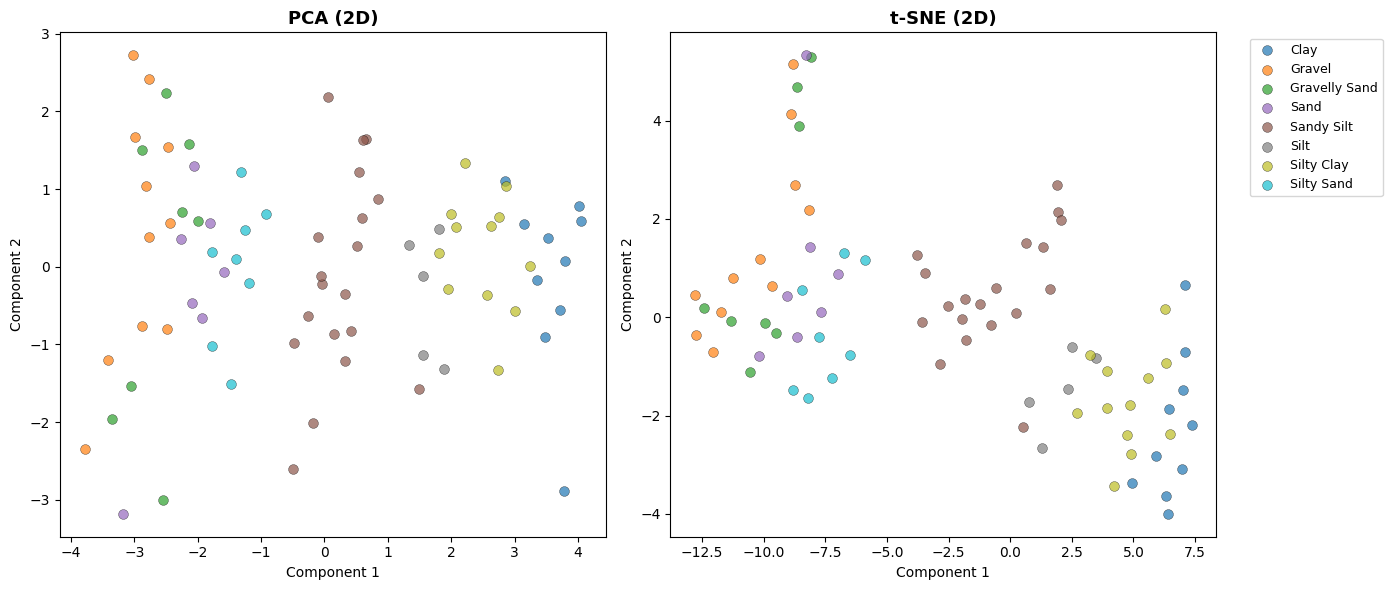

PCA: preserves global structure (overall variance)
t-SNE: preserves local structure (neighborhood relationships)
t-SNE often reveals clusters that PCA misses.


In [11]:
# ─────────────────────────────────────────────────────
# t-SNE VISUALIZATION
# ─────────────────────────────────────────────────────
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, random_state=42, perplexity=20)
X_tsne = tsne.fit_transform(X_scaled)

# ── Compare PCA vs t-SNE ──
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, (data, title) in zip(axes, [(X_pca_2d, 'PCA (2D)'), (X_tsne, 't-SNE (2D)')]):
    for soil in unique_soils:
        mask = soil_labels == soil
        ax.scatter(data[mask, 0], data[mask, 1],
                    c=[color_map[soil]], label=soil, s=50, alpha=0.7, 
                    edgecolors='black', linewidth=0.3)
    ax.set_title(title, fontweight='bold', fontsize=13)
    ax.set_xlabel('Component 1')
    ax.set_ylabel('Component 2')

axes[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=9)
plt.tight_layout()
plt.savefig('pca_vs_tsne.png', dpi=100, bbox_inches='tight')
plt.show()

print("PCA: preserves global structure (overall variance)")
print("t-SNE: preserves local structure (neighborhood relationships)")
print("t-SNE often reveals clusters that PCA misses.")

## Part 6: Complete Application — Reduce and Visualize

Let us apply PCA to reduce our 8-feature soil dataset to 3 principal components, analyze what each component represents, and visualize the clustering.

---

In [12]:
# ═════════════════════════════════════════════════════
# COMPLETE APPLICATION: PCA ON SOIL DATA
# ═════════════════════════════════════════════════════

# ── Reduce to 3 components ──
pca_3d = PCA(n_components=3)
X_pca_3d = pca_3d.fit_transform(X_scaled)

print("PCA Reduction: 8 features → 3 components")
print("=" * 55)
print(f"Variance retained: {pca_3d.explained_variance_ratio_.sum():.1%}")
print(f"  PC1: {pca_3d.explained_variance_ratio_[0]:.1%}")
print(f"  PC2: {pca_3d.explained_variance_ratio_[1]:.1%}")
print(f"  PC3: {pca_3d.explained_variance_ratio_[2]:.1%}")
print()

# ── Create a clean DataFrame ──
pca_result = pd.DataFrame({
    'PC1': X_pca_3d[:, 0],
    'PC2': X_pca_3d[:, 1],
    'PC3': X_pca_3d[:, 2],
    'soil_type': df['soil_type']
})

print("PCA-Reduced Dataset:")
print(pca_result.head(10))

PCA Reduction: 8 features → 3 components
Variance retained: 92.6%
  PC1: 66.0%
  PC2: 19.5%
  PC3: 7.1%

PCA-Reduced Dataset:
        PC1       PC2       PC3      soil_type
0  3.356452 -0.171154  0.306793           Clay
1 -0.504845 -2.596748 -0.596389     Sandy Silt
2 -1.768358 -1.023002 -0.850531     Silty Sand
3  0.157480 -0.860424 -0.100560     Sandy Silt
4 -2.247109  0.706807 -0.549781  Gravelly Sand
5  2.998555 -0.569567 -0.224274     Silty Clay
6 -2.767013  0.380158 -0.091649         Gravel
7  1.806151  0.173838 -0.363666     Silty Clay
8  3.521414  0.371329  1.203261           Clay
9 -2.479132 -0.798255 -0.302737         Gravel


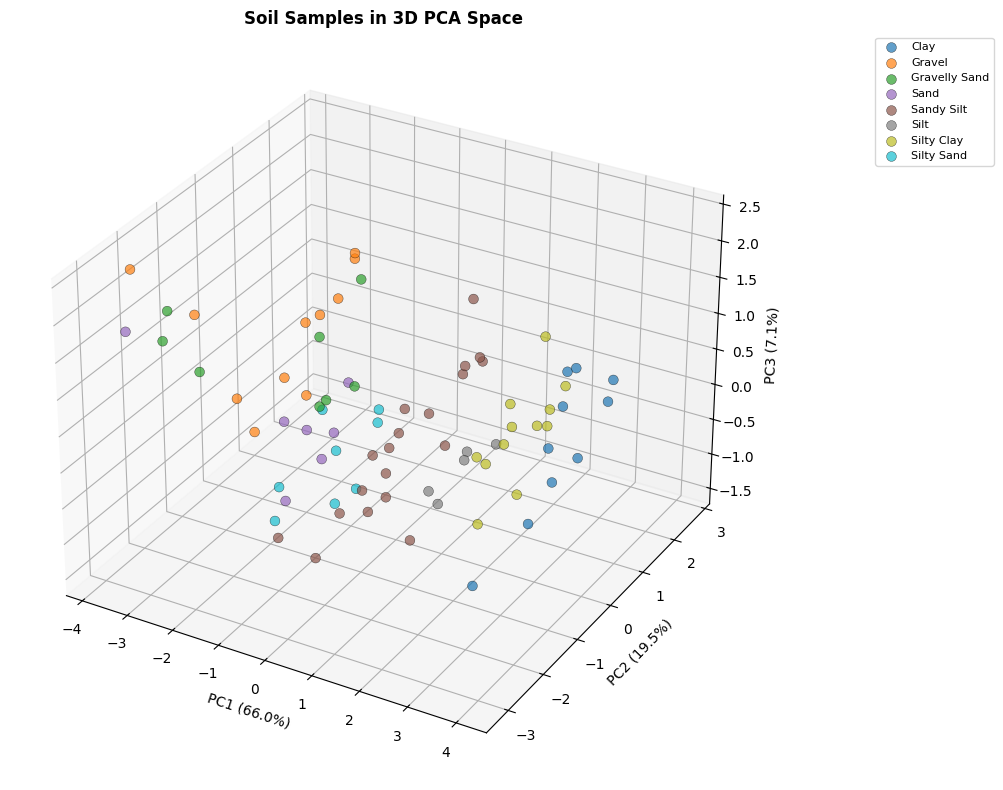

With 3 PCs we capture 92.6% of the information
from 8 original features — a 2.7x compression!


In [13]:
# ─────────────────────────────────────────────────────
# 3D VISUALIZATION
# ─────────────────────────────────────────────────────
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

for soil in unique_soils:
    mask = soil_labels == soil
    ax.scatter(X_pca_3d[mask, 0], X_pca_3d[mask, 1], X_pca_3d[mask, 2],
               c=[color_map[soil]], label=soil, s=50, alpha=0.7, edgecolors='black', linewidth=0.3)

ax.set_xlabel(f'PC1 ({pca_3d.explained_variance_ratio_[0]:.1%})')
ax.set_ylabel(f'PC2 ({pca_3d.explained_variance_ratio_[1]:.1%})')
ax.set_zlabel(f'PC3 ({pca_3d.explained_variance_ratio_[2]:.1%})')
ax.set_title('Soil Samples in 3D PCA Space', fontweight='bold')
ax.legend(bbox_to_anchor=(1.15, 1), loc='upper left', fontsize=8)

plt.tight_layout()
plt.savefig('pca_3d_soil.png', dpi=100, bbox_inches='tight')
plt.show()

print(f"With 3 PCs we capture {pca_3d.explained_variance_ratio_.sum():.1%} of the information")
print(f"from 8 original features — a {8/3:.1f}x compression!")

---

## Practice Exercises

### Exercise 1: Optimal number of components
Write code that finds the minimum number of PCs needed to retain 95% of variance. How many components is that?

### Exercise 2: Reconstruct from PCA
Transform data to 2 PCs, then transform back using `pca.inverse_transform()`. Calculate the reconstruction error (MSE).

### Exercise 3: PCA for noise reduction
Add random noise to the data (`X_noisy = X_scaled + np.random.normal(0, 0.5, X_scaled.shape)`). Apply PCA with 3 components and inverse_transform. Does PCA help denoise?

---

In [14]:
# ─────────────────────────────────────────────────────
# EXERCISE 1: Find optimal number of components
# ─────────────────────────────────────────────────────
# pca_full = PCA()
# pca_full.fit(X_scaled)
# cum_var = np.cumsum(pca_full.explained_variance_ratio_)
# n_95 = np.argmax(cum_var >= 0.95) + 1
# print(f"Components for 95% variance: {n_95}")

In [15]:
# ─────────────────────────────────────────────────────
# EXERCISE 2: Reconstruction error
# ─────────────────────────────────────────────────────
# pca_2 = PCA(n_components=2)
# X_reduced = pca_2.fit_transform(X_scaled)
# X_reconstructed = pca_2.inverse_transform(X_reduced)
# mse = np.mean((X_scaled - X_reconstructed) ** 2)
# print(f"Reconstruction MSE with 2 PCs: {mse:.4f}")

In [16]:
# ─────────────────────────────────────────────────────
# EXERCISE 3: PCA for noise reduction
# ─────────────────────────────────────────────────────
# np.random.seed(42)
# X_noisy = X_scaled + np.random.normal(0, 0.5, X_scaled.shape)
# pca_denoise = PCA(n_components=3)
# X_clean = pca_denoise.inverse_transform(pca_denoise.fit_transform(X_noisy))
# noise_mse = np.mean((X_scaled - X_noisy) ** 2)
# clean_mse = np.mean((X_scaled - X_clean) ** 2)
# print(f"Noise MSE: {noise_mse:.4f}, After PCA: {clean_mse:.4f}")

---

## Key Takeaways

1. **The curse of dimensionality** is real in geotechnical ML. Many soil properties are correlated, carrying redundant information. PCA compresses this efficiently.

2. **PCA finds orthogonal axes of maximum variance.** The first few PCs often capture 80-90% of the information in your data.

3. **Always standardize before PCA.** Otherwise, features with larger scales dominate the principal components regardless of their actual importance.

4. **PC loadings reveal what each component means.** In soil data, PC1 often captures the fine-grained vs coarse-grained distinction, while PC2 captures depth-related variation.

5. **t-SNE is for visualization only.** Use PCA for actual dimensionality reduction in ML pipelines; use t-SNE to explore clusters visually.

---

## How This Connects to ML

| What We Did Today | What It Becomes in ML |
|---|---|
| PCA reduction | Preprocessing step to reduce correlated features |
| Explained variance ratio | Guide for choosing number of features |
| PC loadings | Feature interpretation and domain understanding |
| SVD | Foundation of many ML algorithms (recommender systems, NLP) |
| t-SNE visualization | Exploring hidden structure before modeling |
| 3D PCA plot | Checking if soil types are separable (classification feasibility) |

---

*Day 034 of 100 — Keep going!*